In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 51s 0us/step 


In [3]:
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

print("Training labels:", y_train.shape)

Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)
Training labels: (50000, 1)


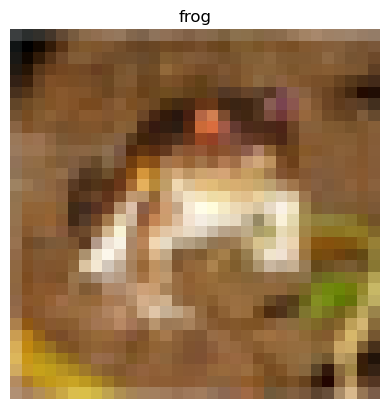

In [8]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat',
    'deer', 'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.imshow(x_train[0])
plt.title(class_names[y_train[0][0]])
plt.axis('off')
plt.show()

In [9]:
#normalize the images using MobileNetV2's preprocessing function.
def preprocess_image(image, label):

    image = tf.image.resize(image, (96, 96))

    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [10]:
#Create training and testing pipelines:
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))

train_ds = train_ds.shuffle(10000)
train_ds = train_ds.map(preprocess_image)
train_ds = train_ds.batch(32).prefetch(tf.data.AUTOTUNE)


test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test))

test_ds = test_ds.map(preprocess_image)
test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)

In [11]:
#Load the pre-trained MobileNetV2 model
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [12]:
base_model.trainable = False

In [13]:
model = keras.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96 (Functional)     │ (None, 3, 3, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
#Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [16]:
#Traain custom classifier
history = model.fit(
    train_ds,
    epochs=3,
    validation_data=test_ds
)

Epoch 1/3


C:\Users\Asus\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 110s 68ms/step - accuracy: 0.8067 - loss: 0.5779 - val_accuracy: 0.8512 - val_loss: 0.4255
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - accuracy: 0.8486 - loss: 0.4367 - val_accuracy: 0.8601 - val_loss: 0.4077
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - accuracy: 0.8657 - loss: 0.3878 - val_accuracy: 0.8581 - val_loss: 0.4093


In [18]:
#Evaluate model
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.8581 - loss: 0.4093
Test Loss: 0.40931957960128784
Test Accuracy: 0.8580999970436096


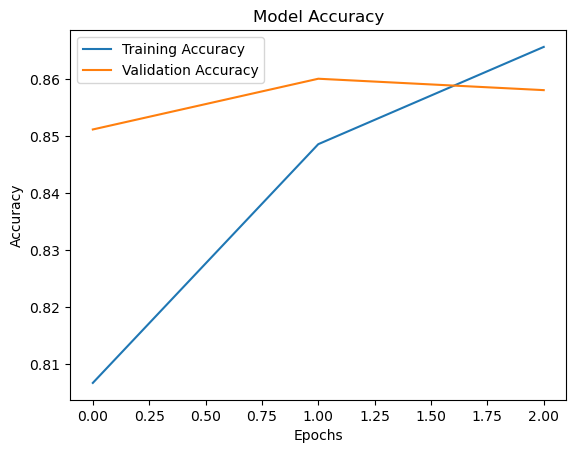

In [19]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

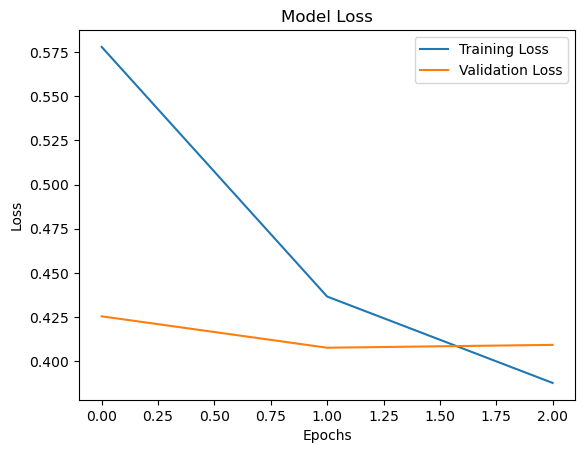

In [20]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [21]:
#Finetune pretrained model
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [22]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [23]:
history_fine = model.fit(
    train_ds,
    epochs=2,
    validation_data=test_ds
)

Epoch 1/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 85s 52ms/step - accuracy: 0.8937 - loss: 0.3045 - val_accuracy: 0.8782 - val_loss: 0.3648
Epoch 2/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 53ms/step - accuracy: 0.9092 - loss: 0.2601 - val_accuracy: 0.8820 - val_loss: 0.3534


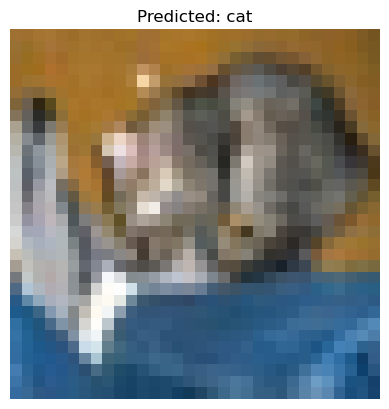

Predicted Class: cat
Actual Class: cat


In [24]:
#Predict an image
image, label = next(iter(test_ds))

prediction = model.predict(image[:1], verbose=0)

predicted_class = np.argmax(prediction[0])

plt.imshow(x_test[0])
plt.title("Predicted: " + class_names[predicted_class])
plt.axis('off')
plt.show()

print("Predicted Class:", class_names[predicted_class])
print("Actual Class:", class_names[int(y_test[0][0])])
